<div class="langswitch">
  <a href="#lang-en">English</a> · <strong>فارسی</strong>
</div>

# خوشه‌بندی سلسله‌مراتبی

![](img/banner.png)

گروه علوم کامپیوتر، دانشگاه فردوسی مشهد


## جای این صفحه در درس

بند ۱۴.۳.۱۲ از {cite}`hastie2009esl` (صص ۵۲۰–۵۲۸) جانشین انتخاب $K$ پیش از دیدن داده است. به‌جای یک افراز، **خانواده‌ای تودرتو** از افرازها می‌سازد، یکی برای هر سطح، و انتخاب سطح را به کاربر می‌سپارد — پس از آنکه ساختار دیده شد.

این صفحه همان بند را گسترش می‌دهد: دو الگوواره، دندروگرام و آنچه می‌توان از آن خواند، سه قاعدهٔ پیوند و عیب هر یک، الگوریتم تقسیمی، و هشدارها. کاربردی بر هیستوگرام رنگ تصویرها در [صفحهٔ خوشه‌بندی تصویر](Image-Clustering-Hierarchical.ipynb) است؛ این صفحه روش پشت آن است.

### در پایان باید بتوانید

* خوشه‌بندی تجمعی و تقسیمی را توصیف کنید و بگویید هر یک چه چیزی از کاربر می‌خواهد؛
* دندروگرام را بخوانید، آن را ببرید و بدانید ارتفاع چه معنایی دارد؛
* بگویید قاعدهٔ پیوند چیست، سه قاعدهٔ استاندارد را بنویسید و عیب هر کدام را نام ببرید؛
* توضیح دهید چرا پیوند تک و کامل تبدیل‌های یکنوای فاصله‌ها را نادیده می‌گیرند و میانگین گروهی نه؛
* همبستگی کوپنتیک را حساب کنید و بگویید چرا تضمین ضعیفی است.


## ۱. دو الگوواره

**تجمعی** (پایین‌به‌بالا) با $N$ خوشهٔ تک‌عضوی آغاز می‌کند و در هر یک از $N-1$ گام، دو خوشه‌ای را ادغام می‌کند که نامتشابهی میان‌گروهی کمینه دارند. **تقسیمی** (بالابه‌پایین) با یک خوشهٔ شامل همه آغاز می‌کند و در هر گام یکی از خوشه‌های موجود را به دو می‌شکند و شکستی را برمی‌گزیند که نامتشابهی میان‌گروهی بیشترین باشد. هر دو $N-1$ سطح می‌سازند و هر دو را می‌توان درختی دودویی ریشه‌دار کشید: برگ‌ها مشاهده‌ها، هر گرهٔ درونی یک ادغام (یا شکستن)، و ریشه کل مجموعه‌داده.

درخت وقتی تصویر می‌شود که ارتفاع‌ها معقول برگزیده شوند. همهٔ روش‌های تجمعی، و برخی تقسیمی‌ها، **یکنوا** هستند: نامتشابهی‌ای که خوشه‌ها در آن ادغام می‌شوند با سطح افزایش می‌یابد. آن‌گاه جای عمودی هر گره را می‌توان متناسب با مقدار ادغامش کشید، برگ‌ها در صفر، و نتیجه یک **دندروگرام** است.

آنچه دندروگرام *نیست*، مدلی از داده است. کتاب یک بند به این هشدار می‌دهد (ص ۵۲۲):

> روش‌های سلسله‌مراتبی ساختار سلسله‌مراتبی را تحمیل می‌کنند، چه چنین ساختاری واقعاً در داده باشد چه نباشد.

توصیهٔ حاشیه‌ای در پی می‌آید: تصویر توصیفی است از خوشه‌بندی‌ای که الگوریتم تولید کرده، نه از خود داده.

## ۲. دندروگرام برای چه چیزی قابل‌اعتماد است

بریدن افقی دندروگرام، داده را به خوشه‌هایی می‌شکند که شاخه‌هایشان از خط برش می‌گذرند، که دقیقاً یعنی «وقتی نامتشابهی از آستانه گذشت، ادغام را متوقف کن». یک برش یک افراز می‌دهد؛ همهٔ برش‌ها با هم خانوادهٔ تودرتو را.

دو عدد می‌سنجند که درخت تا چه حد نامتشابهی‌هایی را که از آن‌ها ساخته شده بازنمایی می‌کند:

* **نامتشابهی کوپنتیک** $C_{ii'}$ دو مشاهده، ارتفاعی است که در آن نخستین‌بار به یک خوشه می‌پیوندند؛
* **همبستگی کوپنتیک** همبستگی میان $N(N-1)/2$ نامتشابهی ورودی و همتایان کوپنتیکشان است.

همبستگی بالا شبیه اعتبارسنجی به گوش می‌آید و کتاب توضیح می‌دهد چرا نیست. $C_{ii'}$ در میان $N(N-1)/2$ جفت تنها $N-1$ مقدار متمایز دارد، پس درخت درجه‌های آزادی بسیار کمتری از ماتریس دارد؛ و آن‌ها باید **نامساوی فرامتری** را برآورده کنند:

$$
C_{ii'} \le \max\{C_{ik}, C_{ki'}\}
\qquad \text{(14.40)}
$$

برای هر سه‌تایی. در تصویری اقلیدسی این یعنی هر مثلث باید متساوی‌الساقین باشد و ضلع نابرابرش از دو ضلع برابر بلندتر نباشد — هندسه‌ای بسیار ویژه. نامتشابهی‌های عمومی چنین نیستند، پس همبستگی می‌سنجد درخت تا چه حد به شکلی نزدیک می‌شود که به‌هرحال مجبور به داشتنش است.


## ۳. پیوند: «فاصلهٔ دو خوشه» یعنی چه

ادغام تجمعی به نامتشابهی‌ای میان *گروه‌ها* نیاز دارد که از نامتشابهی‌های جفتی اعضایشان حساب می‌شود. سه قاعده استانداردند، با $G$ و $H$ دو گروه:

| قاعده | تعریف | گرایش |
|---|---|---|
| تک (SL) | $d_{SL}(G,H) = \min_{i\in G,\, i'\in H} d_{ii'}$ (۱۴.۴۱) | زنجیره‌سازی: خوشه‌های بلند و نازک |
| کامل (CL) | $d_{CL}(G,H) = \max_{i\in G,\, i'\in H} d_{ii'}$ (۱۴.۴۲) | خوشه‌های جمع‌وجور، شاید نقض نزدیکی |
| میانگین گروهی (GA) | $d_{GA}(G,H) = \frac{1}{N_G N_H}\sum_{i\in G}\sum_{i'\in H} d_{ii'}$ (۱۴.۴۳) | میانه‌رو، وابسته به مقیاس |

هر کدام شکست مشخصه‌ای دارد و شکست‌ها دوگان هم‌اند:

* **پیوند تک** برای نزدیک خواندن دو گروه تنها یک نامتشابهی کوچک می‌خواهد، پس با خوشحالی مشاهده‌ها را از راه واسطه‌های نزدیک زنجیره می‌کند. نتیجه خوشه‌ای با **قطر** بسیار بزرگ $D_G = \max_{i,i'\in G} d_{ii'}$ (۱۴.۴۴) است، بلند و نازک. این همان عیب کلاسیک «زنجیره‌سازی» است.
* **پیوند کامل** می‌خواهد *همهٔ* جفت‌های میان‌گروهی کوچک باشند، پس خوشه‌های جمع‌وجور می‌سازد — و می‌تواند مشاهده‌ای را در خوشه‌ای بگذارد که اعضای دیگرش از آن دورترند تا اعضای خوشهٔ دیگر. جمع‌وجور، ولی نه «نزدیک».
* **میانگین گروهی** میان این دو می‌نشیند و بهایش را با از دست دادن ناوردایی مقیاس می‌دهد: اعمال تبدیل یکنوای صعودی $h$ بر نامتشابهی‌ها میانگین را عوض می‌کند، پس نتیجه می‌تواند عوض شود. تک و کامل فقط از *ترتیب* فاصله‌ها بهره می‌برند و نسبت به هر چنین $h$ ناوردا هستند. کتاب این ناوردایی را استدلالی به سودشان می‌گیرد.

یک استدلال دیگر هم هست، از نوعی که این درس به آن اهمیت می‌دهد. اگر هر خوشه نمونه‌ای از چگالی $p_k$ باشد، آن‌گاه $d_{GA}(G,H)$ برآوردگر

$$
\iint d(x,x')\, p_G(x)\, p_H(x')\, dx\, dx',
\qquad \text{(14.45)}
$$

است، خاصیتی از دو چگالی — و با $N \to \infty$ همگرا می‌شود. پیوند تک به صفر و پیوند کامل به بی‌نهایت همگرا می‌شوند، مستقل از چگالی‌ها، پس معلوم نیست هیچ‌کدام چه کمیت جامعه‌ای را برآورد می‌کنند.

## ۴. سه درخت روی یک مجموعه‌داده

دادهٔ زیر سه گروه در صفحه است به‌علاوهٔ **پُلی** از نقطه‌ها که دو گروه اول را به هم می‌دوزد؛ همان پیکربندی‌ای که پیوند تک برای شکست خوردن در آن ساخته شد.


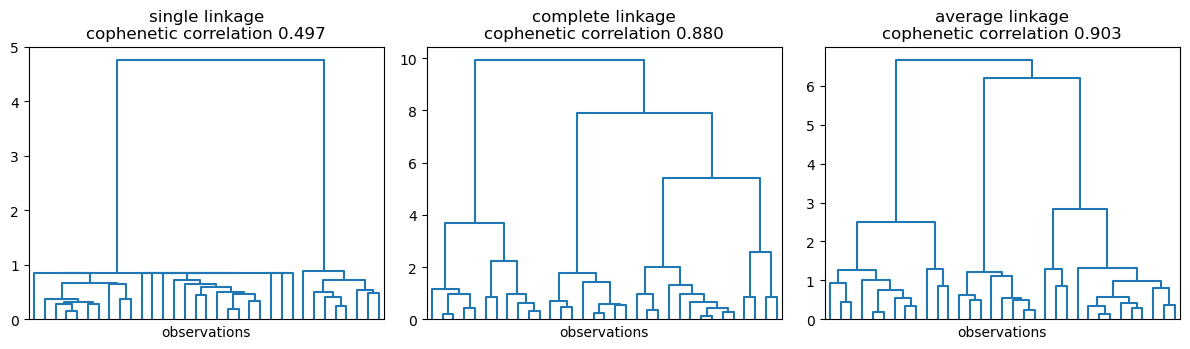

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist, squareform

rng = np.random.default_rng(0)
g1 = rng.normal((-4.0, 0.0), 0.6, size=(8, 2))
g2 = rng.normal((4.0, 0.0), 0.6, size=(8, 2))
g3 = rng.normal((0.0, 5.0), 0.6, size=(8, 2))
bridge = np.column_stack([np.linspace(-3.4, 3.4, 9), np.linspace(-0.4, 0.4, 9)])
X = np.vstack([g1, g2, g3, bridge])
truth = np.r_[np.repeat([0, 1, 2], 8), np.full(9, 3)]
n = len(X)

D1 = pdist(X)
Dfull = squareform(D1)

methods = ["single", "complete", "average"]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, method in zip(axes, methods):
    Z = linkage(D1, method=method)
    dendrogram(Z, ax=ax, no_labels=True, color_threshold=0)
    c, coph = cophenet(Z, D1)
    ax.set_title(f"{method} linkage\ncophenetic correlation {c:.3f}")
    ax.set_xlabel("observations")
plt.tight_layout()
plt.show()

همبستگی کوپنتیک در سه پنل متفاوت است و نکتهٔ کتاب این است که چیزی را فیصله نمی‌دهد: هر سه درخت توصیف معتبری از *توالی ادغام خودشان* هستند. آنچه تفاوت دارد شکل جواب است، و همان بدون هیچ ضریبی دیده می‌شود.

سلول بعد تفاوت را عددی می‌کند: هر درخت را در سه خوشه ببرید و قطر پهن‌ترین خوشه و توافق با گروه‌های واقعی را بسنجید.


In [2]:
from sklearn.metrics import adjusted_rand_score


def diameters(labels, Dfull):
    out = []
    for k in np.unique(labels):
        idx = np.where(labels == k)[0]
        out.append(Dfull[np.ix_(idx, idx)].max() if len(idx) > 1 else 0.0)
    return np.array(out)


print(f"{'method':>9} {'ARI vs truth':>13} {'max diameter':>14} {'clusters':>9}")
for method in methods:
    Z = linkage(D1, method=method)
    labels = fcluster(Z, t=3, criterion="maxclust")
    print(f"{method:>9} {adjusted_rand_score(truth, labels):13.3f} "
          f"{diameters(labels, Dfull).max():14.2f} {len(np.unique(labels)):9d}")

   method  ARI vs truth   max diameter  clusters
   single         0.271           9.94         3
 complete         0.581           5.39         3
  average         0.570           4.55         3


پیوند تک پل و هر دو گروهی را که به هم می‌دوزد در یک خوشه با قطری به اندازهٔ کل پل می‌گذارد؛ کامل و میانگین گروه‌ها را جمع‌وجور نگه می‌دارند. روی داده‌ای که گروه‌ها واقعاً جمع‌وجور و خوب‌جدا هستند، هر سه هم‌نظرند — و این دقیقاً همان وضعیتی است که در آن انتخاب اهمیتی ندارد.

## ۵. ناوردایی مقیاس، بررسی‌شده

ادعا این است که تک و کامل فقط به ترتیب نامتشابهی‌ها وابسته‌اند، در حالی که میانگین گروهی از مقدارشان بهره می‌برد. سلول زیر $h(d) = d^3$ را اعمال می‌کند — اکیداً صعودی، پس ترتیب دست‌نخورده می‌ماند — سه درخت را از فاصله‌های تبدیل‌شده بازمی‌سازد و افرازهای سه‌خوشه‌ای حاصل را با نسخه‌های تبدیل‌نشده مقایسه می‌کند.


In [3]:
D2 = D1 ** 3
print(f"{'method':>9} {'same partition after d -> d^3':>32} {'ARI':>6}")
for method in methods:
    labels_1 = fcluster(linkage(D1, method=method), t=3, criterion="maxclust")
    labels_2 = fcluster(linkage(D2, method=method), t=3, criterion="maxclust")
    same = np.array_equal(labels_1, labels_2)
    print(f"{method:>9} {str(same):>32} {adjusted_rand_score(labels_1, labels_2):6.3f}")

   method    same partition after d -> d^3    ARI
   single                             True  1.000
 complete                             True  1.000
  average                            False  0.897


تک و کامل «True» می‌دهند: با همان داده و همان ترتیب، دقیقاً همان درخت را بازمی‌سازند، چون $\min$ و $\max$ یک تابع یکنوا همان تابع یکنوای $\min$ و $\max$ است. میانگین گروهی می‌تواند «False» بدهد، و وقتی می‌دهد دلیلش این است که میانگین مکعب‌ها مکعب میانگین نیست: سه فاصلهٔ کوچک و یکی بزرگ جایشان را عوض می‌کنند.

این کنجکاوی نیست. فاصله‌ها اغلب دوباره‌مقیاس می‌شوند — به همبستگی، به شباهت، به رتبه — و پرسش «آیا خوشه‌بندی از این مقیاس‌بندی جان سالم به در می‌برد؟» برای دو قاعده از سه پاسخ مشخصی دارد و برای سومی ندارد.


## ۶. خوشه‌بندی تقسیمی

خوشه‌بندی بالابه‌پایین بسیار کمتر مطالعه شده است. استفاده از K-means با $K = 2$ در هر گره نسخهٔ بدیهی است و دو مشکل آن روش را به ارث می‌برد: به پیکربندی آغازین وابسته است، و توالی شکست‌ها لازم نیست یکنوا باشد، پس نمی‌توان آن را دندروگرام درستی کشید.

کتاب الگوریتم مکناتون-اسمیت را می‌دهد که هر دو را دور می‌زند. با یک گروه $G$ شامل همه آغاز کنید. مشاهده‌ای را بردارید که میانگین نامتشابهی‌اش از بقیه بیشترین است و آن را نخستین عضو گروه دوم $H$ کنید. سپس مکرراً مشاهده‌ای از $G$ را به $H$ ببرید که

$$
\text{(میانگین نامتشابهی تا } H) - \text{(میانگین نامتشابهی تا بقیهٔ } G)
$$

بیشترین است، و وقتی این تفاوت منفی شد بایستید. نتیجه شکستن به دو گروه است؛ آن را بازگشتی اعمال کنید و در هر سطح خوشه‌ای را برای شکستن بعدی برگزینید که قطرش (۱۴.۴۴) بیشترین است.


In [4]:
def average_to(group, i, Dfull):
    others = [j for j in group if j != i]
    return Dfull[i, others].mean() if others else 0.0


def ms_split(members, Dfull):
    """Macnaughton Smith's two-way split of one group."""
    members = list(members)
    if len(members) < 2:
        return members, []
    first = max(members, key=lambda i: average_to(members, i, Dfull))
    G, H = [i for i in members if i != first], [first]
    while len(G) > 1:
        scores = {i: Dfull[i, H].mean() - average_to(G, i, Dfull) for i in G}
        best = max(scores, key=scores.get)
        if scores[best] <= 0:
            break
        G.remove(best)
        H.append(best)
    return G, H


def divisive(K, Dfull, n):
    groups = [list(range(n))]
    while len(groups) < K:
        groups.sort(key=lambda g: -Dfull[np.ix_(g, g)].max())
        biggest = groups.pop(0)
        A, B = ms_split(biggest, Dfull)
        groups.extend([g for g in (A, B) if g])
    labels = np.zeros(n, dtype=int)
    for k, g in enumerate(groups):
        labels[g] = k
    return labels


for K in (2, 3):
    labels = divisive(K, Dfull, n)
    sizes = sorted(np.bincount(labels), reverse=True)
    print(f"K = {K}: cluster sizes {sizes}, ARI with the true groups "
          f"{adjusted_rand_score(truth, labels):.3f}")

K = 2: cluster sizes [17, 16], ARI with the true groups -0.048
K = 3: cluster sizes [16, 9, 8], ARI with the true groups -0.071


توالی شکست‌ها به‌حکم ساخت تودرتو است — سطح $K+1$ سطح $K$ را پالایش می‌کند — و همین چیزی است که K-means نمی‌تواند تضمین کند، و همان که باعث می‌شود [مثال تومور](Tumor-Microarray-Example.md) جواب سلسله‌مراتبی را ترجیح دهد.

ARI چاپ‌شدهٔ بالا در عمل هشدار دوم این بند است: روی این داده نخستین شکست از میان گروه‌ها می‌گذرد، پس تودرتو بودن تضمین می‌کند که سطح‌ها یکدیگر را پالایش کنند و هیچ نمی‌گوید آیا هیچ سطحی درست است. سلسله‌مراتب ساختاری است که رویه همیشه تولید می‌کند؛ سلسله‌مراتب *سودمند* خاصیتی از داده است.

## ۷. مرتب‌کردن مشاهده‌ها

چون برگ‌های دندروگرام در هر گرهٔ درونی می‌توانند بازتاب شوند، درخت در بهترین حالت یک ترتیب *جزئی* را تثبیت می‌کند. کتاب قاعده‌ای می‌افزاید (پیش‌فرض S-PLUS: در هر ادغام، زیردرخت جمع‌وجورتر را سمت چپ بگذار) و با آن هر دو محور ماتریس بیان را مرتب می‌کند و شکل ۱۴.۱۴ را می‌سازد. این مرتب‌سازی جدولی را به تصویر تبدیل می‌کند: ستون‌های همسایه نمونه‌های مشابه‌اند، سطرهای همسایه ژن‌هایی که رفتار یکسان دارند، و بلوک‌ها دیده می‌شوند.

## خلاصه

* خوشه‌بندی تجمعی جفت نزدیک‌تر را $N-1$ بار ادغام می‌کند؛ تقسیمی ناهمگن‌ترین گروه را می‌شکند. هر دو خانواده‌ای تودرتو می‌دهند، نه یک افراز.
* دندروگرام خواندنی است چون ارتفاع ادغام‌ها یکنواست؛ برش افقی $K$ را پس از دیدن داده برمی‌گزیند.
* پیوند تک زنجیره می‌سازد، پیوند کامل خوشه‌های جمع‌وجور ولی نه لزوماً نزدیک می‌دهد، و میانگین گروهی میانه‌رویی است که به مقیاس فاصله‌ها وابسته است.
* همبستگی کوپنتیک می‌سنجد نامتشابهی‌ها تا چه حد درخت‌گونه‌اند، و نامساوی فرامتری می‌گوید «درخت‌گونه بودن» چقدر محدودکننده است.
* K-means با $K$های مختلف خانوادهٔ تودرتو **نمی‌دهد**؛ خوشه‌بندی سلسله‌مراتبی می‌دهد، و همین است که کتاب برای دادهٔ میکروآرایه آن را ترجیح می‌دهد.


## تمرین‌ها

1. هر سه درخت را در چهار خوشه ببرید و جدول ARI و قطرها را دوباره حساب کنید. کدام روش زیر تغییر $K$ پایدار است؟
2. پل را از داده حذف کنید و مقایسه را تکرار کنید. آیا پیوند تک هنوز شکست می‌خورد؟
3. نامساوی فرامتری را برای درختی کوچک با حساب همهٔ فاصله‌های کوپنتیک (`cophenet`) بررسی کنید. سه‌تایی بیابید که نابرابری در آن تنگ است.
4. مجموعه‌داده‌ای بسازید که میانگین گروهی افرازش را زیر $h(d) = d^3$ عوض کند و توضیح دهید کدام میانگین جابه‌جا شد.
5. الگوریتم تقسیمی را با K-means ($K=2$) به‌جای مکناتون-اسمیت پیاده کنید و یکنوا بودن ارتفاع‌های شکست را بررسی کنید. هیچ‌وقت کاهش می‌یابد؟
6. دادهٔ زنبق را با سه پیوند خوشه‌بندی کنید، در سه خوشه ببرید و با برچسب گونه‌ها مقایسه کنید. کدام قاعده *setosa* را اول می‌یابد؟


## منابع

* دو الگوواره، دندروگرام، همبستگی کوپنتیک، (۱۴.۴۰)–(۱۴.۴۵)، الگوریتم مکناتون-اسمیت و شکل ۱۴.۱۴: بند ۱۴.۳.۱۲ از {cite}`hastie2009esl`، صص ۵۲۰–۵۲۸.
* کاربرد بر هیستوگرام تصویر، که همان توابع `scipy` را به کار می‌برد: [خوشه‌بندی سلسله‌مراتبی تصویر](Image-Clustering-Hierarchical.ipynb).
* برتری خانوادهٔ تودرتو برای دادهٔ تومور: [مثال تومور](Tumor-Microarray-Example.md)، بند ۱۴.۳.۸.
